# Proyecto 3 — Series de tiempo: ¿el pasado dice algo del futuro?

Este notebook responde una pregunta que suena simple y decide toda la industria:

> Si sé lo que hizo SPY ayer, ¿sé algo sobre lo que hará hoy?

Spoiler: para la **dirección** (sube/baja), casi nada. Para la **volatilidad** (cuánto se va a mover), bastante. Esa asimetría es la base de la gestión de riesgo moderna y de por qué los modelos que "predicen el precio" fracasan mientras los que predicen el riesgo funcionan.

**Este notebook es interactivo.** Varias celdas muestran sliders: muévelos y el gráfico se recalcula. Si no aparecen, corre en la terminal `.venv/bin/python -m pip install ipywidgets` y recarga la página.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact, IntSlider, FloatSlider, Button, Output, VBox

from quantlab import (load_prices, log_returns, acf, acf_confidence_band,
                      garch_fit, garch_forecast, simulate_garch, volatility_regime,
                      simulate_gbm, simulate_bootstrap, estimate_params,
                      value_at_risk, conditional_var)

plt.rcParams["figure.figsize"] = (12, 4.5)
sns.set_theme(style="whitegrid")

prices = load_prices(["SPY", "TLT", "GLD", "TSLA"], start="2019-01-01")
lrets = log_returns(prices)
spy = lrets["SPY"]

## 1. Autocorrelación: la serie comparada con ella misma

**Correlación** ya la conoces: cuánto se mueven juntas dos cosas. **Autocorrelación** es lo mismo, pero entre una serie y *ella misma desplazada k días*. Si la autocorrelación a 1 día es alta, "lo que pasó ayer se repite hoy" y hay algo que explotar. Si es ~0, ayer no informa hoy.

Mueve el slider: cada punto es un día; eje X = retorno hace `k` días, eje Y = retorno hoy.

In [23]:
@interact(k=IntSlider(value=1, min=1, max=20, description="lag (días)"))
def scatter_lag(k):
    x, y = spy.shift(k).dropna(), spy.iloc[k:]
    x, y = x.align(y, join="inner")
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(x, y, s=6, alpha=0.4)
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_xlabel(f"retorno hace {k} días"); ax.set_ylabel("retorno hoy")
    ax.set_title(f"SPY: correlación = {np.corrcoef(x, y)[0, 1]:+.3f}")
    ax.set_xlim(-0.12, 0.12); ax.set_ylim(-0.12, 0.12)
    plt.show()

interactive(children=(IntSlider(value=1, description='lag (días)', max=20, min=1), Output()), _dom_classes=('w…

**Qué mirar:** una nube sin forma, correlación ≈ 0 para cualquier lag. Si ayer subió, hoy puede pasar cualquier cosa. Esto es lo que se llama **mercado eficiente** en su versión débil: la información del pasado ya está en el precio, así que no queda nada que exprimir mirando la gráfica.

Ahora el giro. En vez de mirar el retorno, miremos su **tamaño** (el retorno al cuadrado, que ignora el signo):

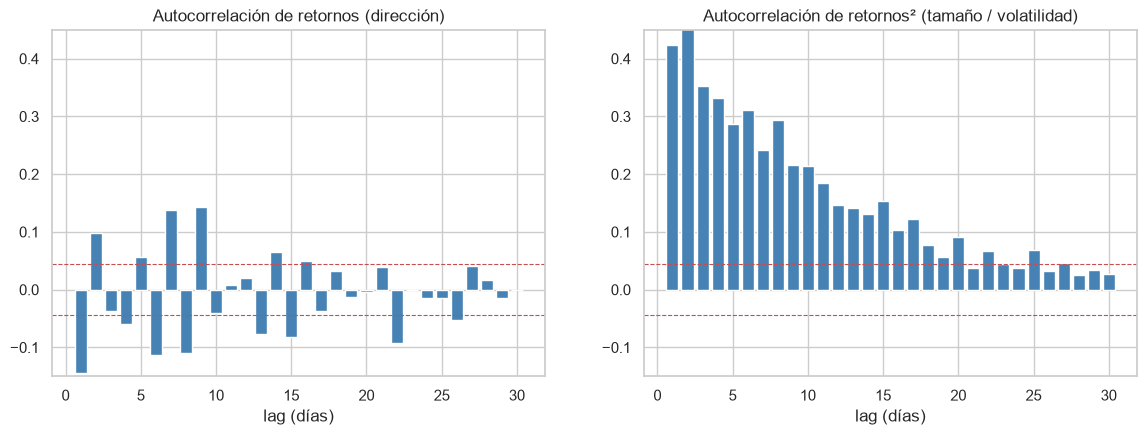

In [32]:
lags = 30
band = acf_confidence_band(len(spy))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (serie, titulo) in zip(axes, [(spy, "retornos (dirección)"), (spy**2, "retornos² (tamaño / volatilidad)")]):
    a = acf(serie, lags)
    ax.bar(range(1, lags + 1), a, color="steelblue")
    ax.axhline(band, color="r", ls="--", lw=0.8); ax.axhline(-band, color="r", ls="--", lw=0.8)
    ax.set_title(f"Autocorrelación de {titulo}"); ax.set_xlabel("lag (días)")
    ax.set_ylim(-0.15, 0.45)
plt.show()

**Qué mirar:** izquierda, todo dentro de las líneas rojas (ruido). Derecha, barras muy por encima durante semanas. Traducción: **no sé si mañana sube o baja, pero si hoy hubo un movimiento grande, mañana probablemente también lo habrá**. La volatilidad viene en rachas. Esto es lo que el bootstrap del proyecto 2 rompía al barajar los días, y lo que GARCH (sección 4) va a modelar.

## 2. Juego: ¿real o aleatorio?

Si la dirección es impredecible, un precio real debería parecerse a un **paseo aleatorio** (random walk): cada día suma un ruido y ya. Vamos a comprobarlo con tus ojos. De los cuatro gráficos, **uno es SPY real** (un tramo de 250 días) y tres son simulados con la misma media y volatilidad. Adivina cuál y pulsa el botón.

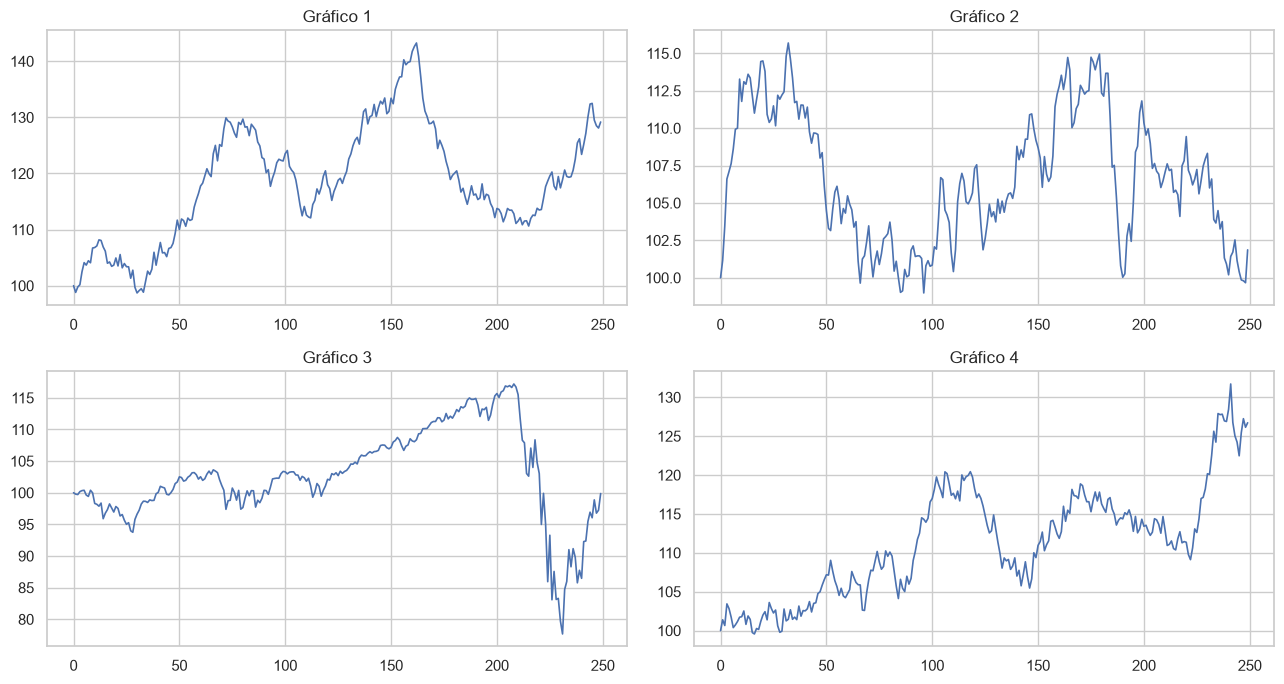

In [25]:
rng = np.random.default_rng()
mu, sigma = estimate_params(spy)
start = rng.integers(0, len(prices) - 250)
real = prices["SPY"].iloc[start:start + 250].to_numpy()
real = real / real[0] * 100
fakes = [simulate_gbm(100, mu, sigma, n_days=249, n_paths=1, seed=int(rng.integers(1e9)))[:, 0] for _ in range(3)]
series = fakes + [real]
orden = rng.permutation(4)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, ax in zip(orden, axes.ravel()):
    ax.plot(series[i], lw=1.2); ax.set_title(f"Gráfico {list(orden).index(i) + 1}")
plt.tight_layout(); plt.show()

out = Output()
btn = Button(description="Revelar", button_style="info")
def revelar(_):
    with out:
        out.clear_output()
        print(f"El real es el Gráfico {list(orden).index(3) + 1}.")
btn.on_click(revelar)
display(VBox([btn, out]))

**Qué mirar:** casi nadie acierta más que el azar (ejecuta la celda varias veces). Tu cerebro ve "tendencias", "soportes" y "patrones" en las tres series que son ruido puro. Esa es la trampa del análisis técnico: el ojo humano está diseñado para encontrar patrones, existan o no. En quant, si no sobrevive a un test estadístico, no existe.

## 3. Estacionariedad: por qué modelamos retornos y no precios

Una serie es **estacionaria** si sus propiedades (media, dispersión) no cambian con el tiempo. Todo modelo estadístico lo asume: si aprendes de datos cuya media se mueve, aprendes una media que ya no existe cuando la usas.

- El **precio** no es estacionario: SPY a 250 en 2019 y a 600 en 2026 no tienen "una media".
- El **retorno** sí (aproximadamente): la media diaria de 2019 y la de 2026 son igualmente ~0.04%.

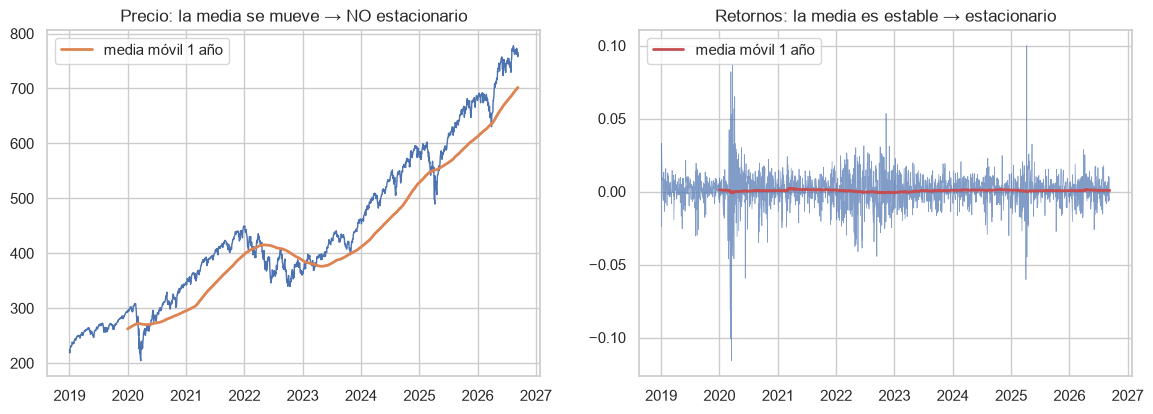

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
p = prices["SPY"]
axes[0].plot(p, lw=1); axes[0].plot(p.rolling(252).mean(), lw=2, label="media móvil 1 año")
axes[0].set_title("Precio: la media se mueve → NO estacionario"); axes[0].legend()
axes[1].plot(spy, lw=0.5, alpha=0.7); axes[1].plot(spy.rolling(252).mean(), lw=2, color="r", label="media móvil 1 año")
axes[1].set_title("Retornos: la media es estable → estacionario"); axes[1].legend()
plt.show()

**Qué mirar:** la media móvil del precio sube sin parar; la de los retornos es una línea plana en ~0. Por eso desde el proyecto 1 todo se hace sobre retornos. (El test formal se llama **ADF**, *Augmented Dickey-Fuller*; lo que hace es medir si la serie tiende a volver a un nivel o se va a la deriva. Cuando leas "p-value < 0.05 en el ADF" en un paper, significa "es estacionaria".)

Fíjate también en el gráfico de retornos: la media es estable pero la *anchura* de la banda no. Hay zonas estrechas y zonas anchas (marzo 2020). Eso es el clustering de volatilidad otra vez, y nos lleva a GARCH.

## 4. GARCH: modelar una volatilidad que cambia

Hasta ahora tratamos la volatilidad como un número fijo ($\sigma$ = 20%). GARCH dice: la varianza de hoy depende de lo que pasó ayer.

$$\sigma^2_t = \omega + \alpha \cdot r^2_{t-1} + \beta \cdot \sigma^2_{t-1}$$

En palabras: **volatilidad de hoy = un nivel base ($\omega$) + reacción al shock de ayer ($\alpha$) + inercia de la volatilidad de ayer ($\beta$)**.

- $\alpha$ alto: el mercado se asusta rápido con un día malo.
- $\beta$ alto: cuando se asusta, tarda en calmarse.
- $\alpha + \beta$ cerca de 1: los sustos duran mucho. En mercados reales suele dar ~0.98.

Juega con los parámetros y mira cómo aparece el clustering en una serie simulada:

In [27]:
@interact(alpha=FloatSlider(value=0.10, min=0.0, max=0.30, step=0.01, description="alpha"),
          beta=FloatSlider(value=0.85, min=0.0, max=0.98, step=0.01, description="beta"))
def play_garch(alpha, beta):
    if alpha + beta >= 1:
        print("alpha + beta debe ser < 1 (si no, la volatilidad explota)"); return
    omega = (0.20**2 / 252) * (1 - alpha - beta)   # fija la vol de largo plazo en 20%
    r = simulate_garch(omega, alpha, beta, n_days=1000, seed=0)[:, 0]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    axes[0].plot(r, lw=0.6); axes[0].set_ylim(-0.12, 0.12)
    axes[0].set_title(f"retornos simulados | curtosis = {pd.Series(r).kurtosis():.1f} | persistencia = {alpha + beta:.2f}")
    axes[1].bar(range(1, 31), acf(r**2, 30), color="steelblue"); axes[1].set_ylim(-0.1, 0.5)
    axes[1].set_title("autocorrelación de r² (clustering)")
    plt.show()

interactive(children=(FloatSlider(value=0.1, description='alpha', max=0.3, step=0.01), FloatSlider(value=0.85,…

**Qué mirar:** con `alpha = 0, beta = 0` tienes el GBM: ruido uniforme, curtosis 0, sin autocorrelación de r². Sube `alpha` a 0.1 y `beta` a 0.85 y aparecen las rachas, la curtosis se dispara y la ACF de r² se ve igual que la de SPY real. **Los shocks siguen siendo normales**: las colas gordas nacen solas de que la volatilidad cambie. Eso es lo bonito de GARCH: explica las colas gordas con un mecanismo, no las asume.

Ahora lo ajustamos a SPY real. "Ajustar" = buscar los $\omega, \alpha, \beta$ que hacen más probable haber visto exactamente estos datos (máxima verosimilitud). Tarda unos segundos.

alpha = 0.155   beta = 0.805   alpha+beta = 0.959
volatilidad de largo plazo implícita: 17.6%


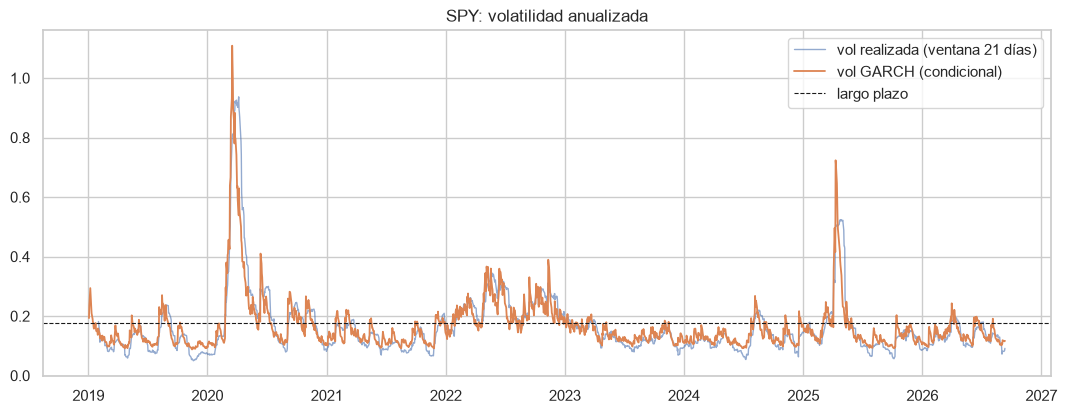

In [28]:
fit = garch_fit(spy)
print(f"alpha = {fit['alpha']:.3f}   beta = {fit['beta']:.3f}   alpha+beta = {fit['persistence']:.3f}")
print(f"volatilidad de largo plazo implícita: {fit['long_run_vol']:.1%}")

vol_21 = spy.rolling(21).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(vol_21, lw=1, alpha=0.6, label="vol realizada (ventana 21 días)")
ax.plot(fit["cond_vol"], lw=1.3, label="vol GARCH (condicional)")
ax.axhline(fit["long_run_vol"], color="k", ls="--", lw=0.8, label="largo plazo")
ax.set_title("SPY: volatilidad anualizada"); ax.legend()
plt.show()

**Qué mirar:** las dos líneas cuentan la misma historia, pero la GARCH reacciona el mismo día del shock mientras la ventana móvil tarda semanas en subir y en bajar (arrastra el evento 21 días). Por eso los bancos usan GARCH y no ventanas móviles para el VaR diario.

### Pronóstico

Una vez ajustado, GARCH pronostica la volatilidad de los próximos días. La propiedad clave: **vuelve a la media**. Si hoy hay pánico, el modelo dice "se irá calmando", a la velocidad que marca $\alpha+\beta$.

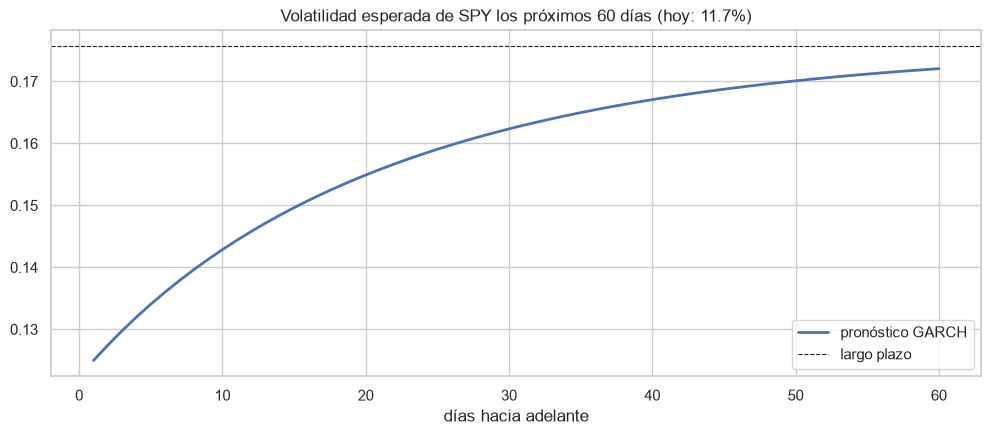

In [29]:
fc = garch_forecast(fit, horizon=60)
plt.plot(range(1, 61), fc, lw=2, label="pronóstico GARCH")
plt.axhline(fit["long_run_vol"], color="k", ls="--", lw=0.8, label="largo plazo")
plt.title(f"Volatilidad esperada de SPY los próximos 60 días (hoy: {fit['cond_vol'].iloc[-1]:.1%})")
plt.xlabel("días hacia adelante"); plt.legend(); plt.show()

## 5. Monte Carlo v3: comparar los tres modelos

Ya tenemos tres formas de simular SPY a un año. Cada una comete un error distinto:

| Modelo | Colas gordas | Rachas de volatilidad | Puede inventar algo que no pasó |
|---|---|---|---|
| GBM | no | no | sí |
| Bootstrap | sí | no | no |
| GARCH | sí (emergen) | sí | sí |

Comparamos el riesgo a un año que cada uno reporta:

In [30]:
N = 10_000
s0 = prices["SPY"].iloc[-1]
mu_d = spy.mean()

fin_gbm = simulate_gbm(s0, mu, sigma, n_paths=N)[-1] / s0 - 1
fin_bs = simulate_bootstrap(s0, spy, n_paths=N)[-1] / s0 - 1
fin_garch = simulate_garch(fit["omega"], fit["alpha"], fit["beta"], n_days=252, n_paths=N, s0=s0, mu_daily=mu_d)[-1] / s0 - 1

def fila(r):
    return {"mediana": np.median(r), "VaR 95%": value_at_risk(r), "CVaR 95%": conditional_var(r),
            "P(caída > 20%)": (r < -0.2).mean(), "P(caída > 30%)": (r < -0.3).mean()}
pd.DataFrame({"GBM": fila(fin_gbm), "Bootstrap": fila(fin_bs), "GARCH": fila(fin_garch)}).T.style.format("{:+.1%}")

,mediana,VaR 95%,CVaR 95%,P(caída > 20%),P(caída > 30%)
GBM,+15.3%,-16.4%,-22.6%,+3.1%,+0.4%
Bootstrap,+17.0%,-14.8%,-21.2%,+2.4%,+0.4%
GARCH,+17.5%,-11.6%,-18.8%,+1.6%,+0.3%


**Qué mirar:** las medianas se parecen; las colas no. La probabilidad de una caída fuerte es donde los modelos discrepan, y esa discrepancia *es* la incertidumbre del modelo. Un quant serio reporta los tres y dice "el riesgo de cola está entre X e Y según el modelo", no un número.

## 6. Régimen de volatilidad: el primer módulo del capstone

Aplicación directa de todo esto: clasificar el momento actual. Comparamos la volatilidad GARCH de hoy con su propia historia: si está en el tercio bajo, régimen *bajo*; tercio alto, *alto*. Esta función es la que la app llamará cada día para avisarte por Telegram cuando el régimen cambie.

In [31]:
for t in ["SPY", "TLT", "GLD", "TSLA"]:
    reg = volatility_regime(garch_fit(lrets[t]))
    print(f"{t:5s}  vol hoy {reg['vol_today']:5.1%}   percentil {reg['percentile']:4.0f}   régimen: {reg['regime'].upper()}")

SPY    vol hoy 11.7%   percentil   26   régimen: BAJO
TLT    vol hoy 11.2%   percentil   18   régimen: BAJO
GLD    vol hoy 25.3%   percentil   91   régimen: ALTO
TSLA   vol hoy 56.9%   percentil   44   régimen: NORMAL


**Para qué sirve saber el régimen:** las estrategias se comportan distinto según él. Momentum funciona en régimen bajo y se destroza en alto; reducir exposición cuando la vol sube (*volatility targeting*) es una de las pocas cosas que mejoran el Sharpe de casi cualquier cartera de forma consistente. Lo usaremos en el proyecto 4.

## 7. Preguntas

1. Un YouTuber muestra un gráfico de precios y dice "aquí se ve claramente el patrón". Después de la sección 2, ¿qué le preguntarías?
2. ¿Por qué se puede predecir la volatilidad pero no la dirección? ¿Qué pasaría si la dirección fuera predecible con la misma facilidad?
3. GARCH tiene shocks normales igual que GBM. ¿De dónde salen entonces las colas gordas?
4. Si hoy SPY está en régimen "alto" con persistencia 0.98, ¿qué esperas de la volatilidad dentro de un mes? ¿Y si la persistencia fuera 0.70?

Siguiente: Proyecto 4, backtesting. Construimos tu primera estrategia, la probamos en el pasado con costos reales, y aprendemos las formas en que un backtest te miente.